# 03 - EDA (Análisis Exploratorio de Datos)

In [1]:
import sys
import os
from pathlib import Path

PROJ_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJ_ROOT)
if str(PROJ_ROOT) not in sys.path:
    sys.path.append(str(PROJ_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


# Cargar el dataset con target ya guardado
df = pd.read_parquet("data/processed/dataset_modelado.parquet")
print(f"Dataset cargado con {len(df)} filas y {len(df.columns)} columnas.")

Dataset cargado con 1979 filas y 36 columnas.


In [2]:
df.describe()

,id_alumno,anio_academico,cohorte_carrera,cohorte_universidad,cambio_plan,antiguedad_carrera,antiguedad_universidad,anios_antes_ingreso_carrera,tuvo_actividad_previa,anios_actividad_previa,...,equivalencias_asignaturas,asignaturas_aprobadas_acumuladas,equivalencias_finales,finales_aprobados_acumulados,porcentaje_avance_cursado,porcentaje_avance_carrera,cantidad_pausas,maxima_duracion_pausa,prox_actividad,abandono
count,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,...,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1979.000000,1436.000000,1979.000000
mean,425.480040,2019.505811,2018.254674,2018.185953,0.863567,1.251137,1.319859,0.068722,0.021223,0.043962,...,5.212734,9.604851,5.032845,8.737241,0.200182,0.198570,0.078828,0.279434,2020.715181,0.302678
std,299.456415,5.040217,5.618097,5.667728,0.343334,2.180457,2.347527,0.933224,0.144163,0.344812,...,5.475907,7.865110,5.117767,7.223479,0.163865,0.164183,0.308051,1.581374,4.958118,0.459533
min,2.000000,2000.000000,2000.000000,1996.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2001.000000,0.000000
25%,170.000000,2019.000000,2016.000000,2016.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,3.000000,1.000000,3.000000,0.063000,0.068000,0.000000,0.000000,2020.000000,0.000000
50%,371.000000,2022.000000,2021.000000,2021.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,3.000000,8.000000,3.000000,8.000000,0.167000,0.182000,0.000000,0.000000,2023.000000,0.000000
75%,652.500000,2023.000000,2022.000000,2022.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,...,9.000000,15.000000,8.000000,14.000000,0.313000,0.318000,0.000000,0.000000,2024.000000,1.000000
max,1523.000000,2023.000000,2023.000000,2023.000000,1.000000,20.000000,25.000000,25.000000,1.000000,5.000000,...,25.000000,43.000000,24.000000,38.000000,0.896000,0.864000,3.000000,21.000000,2026.000000,1.000000


## Tasa de abandono por año de carrera (antiguedad_carrera)

,antiguedad_carrera,total_alumnos,mean,tasa_abandono_%
0,0,999,0.359359,35.94
1,1,462,0.233766,23.38
2,2,222,0.243243,24.32
3,3,105,0.228571,22.86
4,4,61,0.213115,21.31
5,5,38,0.289474,28.95


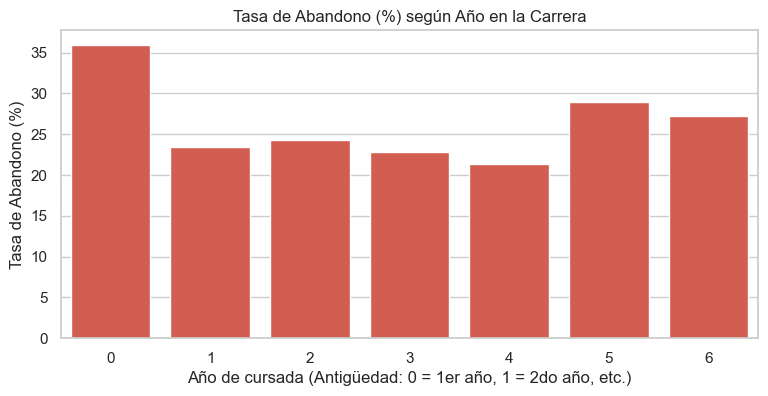

In [3]:
abandono_por_antiguedad = df.groupby("antiguedad_carrera")["abandono"].agg(["count", "mean"]).reset_index()
abandono_por_antiguedad["tasa_abandono_%"] = (abandono_por_antiguedad["mean"] * 100).round(2)
abandono_por_antiguedad.rename(columns={"count": "total_alumnos"}, inplace=True)
display(abandono_por_antiguedad.head(6))

# Gráfico
plt.figure(figsize=(9, 4))
sns.barplot(data=abandono_por_antiguedad[abandono_por_antiguedad["antiguedad_carrera"] <= 6], 
            x="antiguedad_carrera", y="tasa_abandono_%", color="#e74c3c")
plt.title("Tasa de Abandono (%) según Año en la Carrera")
plt.xlabel("Año de cursada (Antigüedad: 0 = 1er año, 1 = 2do año, etc.)")
plt.ylabel("Tasa de Abandono (%)")
plt.show()


- Como se puede evidenciar los años más criticos son el primer y sexto año, esto es importante ya que seria una fuente de información importante para predecir el abandono.

## Abandono vs variables de comportamiento

/var/folders/0v/60k7jjjd6bb32ck6h2nlkpgh0000gp/T/ipykernel_7941/2381855619.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df, x="abandono", y="tasa_aprobacion_asignaturas", palette="Set2")
/var/folders/0v/60k7jjjd6bb32ck6h2nlkpgh0000gp/T/ipykernel_7941/2381855619.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[2], data=df, x="abandono", y="edad", palette="Set2")


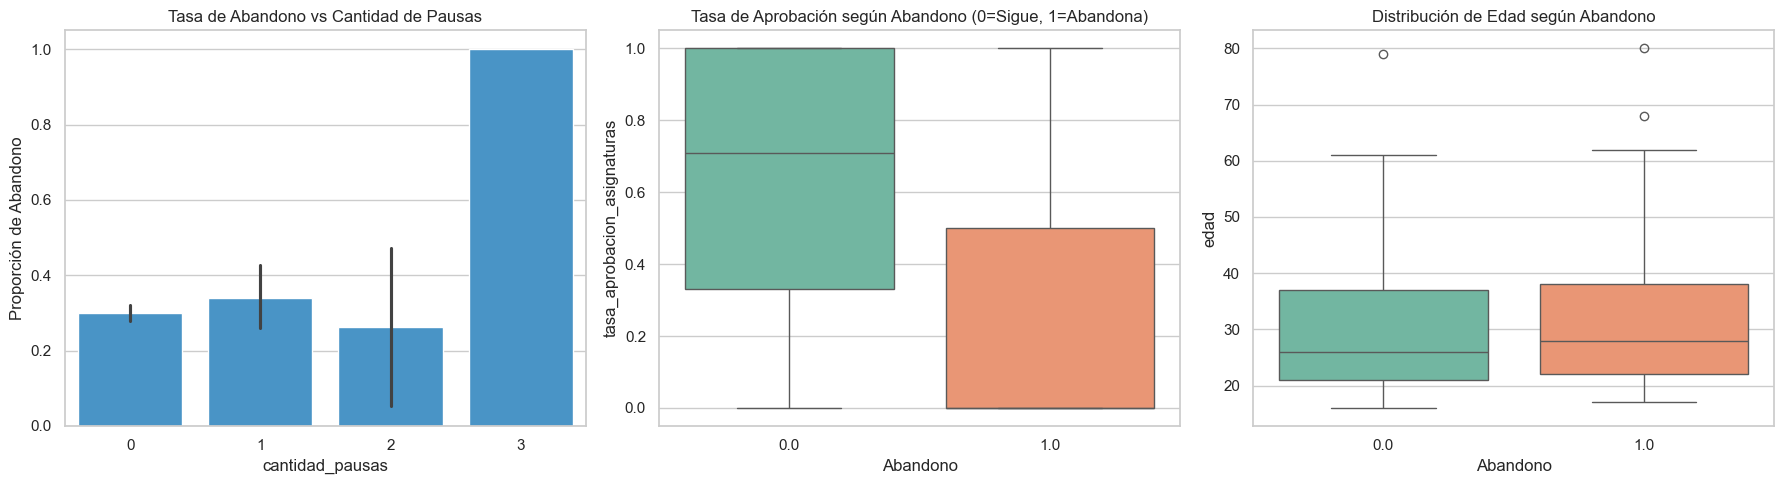

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Abandono vs Pausas
sns.barplot(ax=axes[0], data=df, x="cantidad_pausas", y="abandono", color="#3498db")
axes[0].set_title("Tasa de Abandono vs Cantidad de Pausas")
axes[0].set_ylabel("Proporción de Abandono")

# 2. Abandono vs Tasa de Aprobación
sns.boxplot(ax=axes[1], data=df, x="abandono", y="tasa_aprobacion_asignaturas", palette="Set2")
axes[1].set_title("Tasa de Aprobación según Abandono (0=Sigue, 1=Abandona)")
axes[1].set_xlabel("Abandono")

# 3. Abandono vs Edad
sns.boxplot(ax=axes[2], data=df, x="abandono", y="edad", palette="Set2")
axes[2].set_title("Distribución de Edad según Abandono")
axes[2].set_xlabel("Abandono")

plt.tight_layout()
plt.show()


En este caso encontramos 3 cosas importantes: 

- La primera es que al tener 3 o más pausas es una bandera roja absoluta. Es una regla heurística clave para el sistema de alerta temprana ya que el 100% de los que hacen 3 pausas han abandonado.

- Los que continúan (0.0 - Verde): Tienen una mediana de aprobación cercana al 67% (0.67), y el 75% aprueba más del 25% de lo que cursa.
Los que abandonan (1.0 - Naranja): La caja está aplastada contra el suelo. La gran mayoría tiene una tasa de aprobación de 0.0 a 0.33 (mediana prácticamente en 0 o muy baja) en resumen quien no aprueba materias en el año, está a un paso de irse. Por lo que encontramos que el rendimiento académico inmediato es un gran factor a tener en cuenta.

- Tenemos que en ambos casos, los que abandonan y lo que no, tienen las mismas edades por lo que la edad no es un factor determinante.

## Evolución por Cohorte y Cambio de Plan

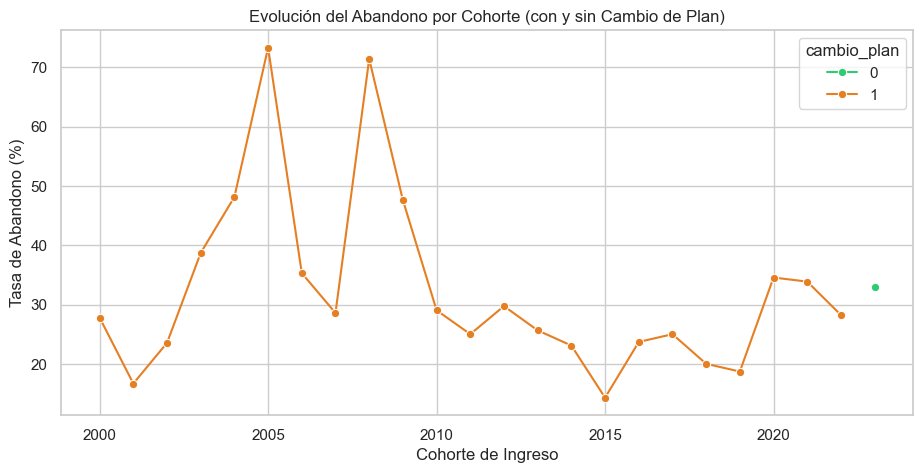

In [5]:
# Evolución por cohorte de carrera
cohorte_summary = df.groupby(["cohorte_carrera", "cambio_plan"])["abandono"].mean().reset_index()
cohorte_summary["tasa_abandono_%"] = cohorte_summary["abandono"] * 100

plt.figure(figsize=(11, 5))
sns.lineplot(data=cohorte_summary, x="cohorte_carrera", y="tasa_abandono_%", 
             hue="cambio_plan", marker="o", palette=["#2ecc71", "#e67e22"])
plt.title("Evolución del Abandono por Cohorte (con y sin Cambio de Plan)")
plt.xlabel("Cohorte de Ingreso")
plt.ylabel("Tasa de Abandono (%)")
plt.show()


In [6]:
df["cambio_plan"].value_counts()

cambio_plan
1    1709
0     270
Name: count, dtype: int64

- La deserción en Psicología muestra tres etapas bien diferenciadas: un período histórico de alta deserción en cohortes antiguas (>70% en 2005 y 2008), una etapa de consolidación y estabilidad entre 2010 y 2019 (promedio 22%), y un claro quiebre estructural a partir de 2020 (subiendo al 38%), atribuible al impacto socio-académico de la pandemia de COVID-19.

- La variable cambio_plan es 1 en el 100% de los registros analizados (migración completa al nuevo plan). No permite comparar planes, y al no tener varianza, no será una variable predictora relevante para los modelos.